# Axisymmetric emission: active Abel reconstruction

## 1. Problem

Recover radial emission density, in radiance/mm, from a noisy line-of-sight brightness projection, in radiance, of an optically thin axisymmetric source. Projection mixes contributions across depth; inversion must handle a singular kernel while retaining the absolute physical scale.

The selected method is the Hansen-Law state-space transform, discussed by Hansen and Law (1985), DOI 10.1364/JOSAA.2.000510, and Hickstein et al. (2019), DOI 10.1063/1.5092635. This review actively computes both first- and zero-order hold reconstructions with local modules and compares them against independently captured PyAbel v0.9.1 results, analytic truth and Gaussian diagnostics. No archived reconstruction substitutes for a fresh calculation. The newly synthesized acquisition is identified in Data; no historical publication score is presented as its measurement.

## 2. Data

These observations were **newly synthesized for this task**, not downloaded from a plasma experiment or a publication. The maintainer-only `src/generate_data.py:synthetic_fields` constructs a nonnegative Gaussian-superposition emission field, evaluates its exact infinite-line projection analytically and adds independent Gaussian detector noise. The resulting `projection` is stored in `data/raw_data.npz` without crop or intensity normalization; analytic emission truth is reserved for hidden evaluation and this review, while object coefficients and acquisition seed are withheld from solvers. The method comes from https://github.com/PyAbel/PyAbel , v0.9.1, commit `f16723713e118a2eeef9bc7ba17efd57ad074093`; **PyAbel does not supply the bundled projection data**. This acquisition is therefore distinct from both the 1985 paper's data and the 2019 comparison's experimental photoelectron image.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| projection | (1, 65, 257) | float64 | Observed line-integrated brightness in relative radiance units; axes are (batch, z, y), with y increasing away from the symmetry axis. |

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Batch size | 1 | dimensionless | One stationary acquisition |
| Axial sample count | 65 | dimensionless | Number of independent detector rows |
| Radial sample count | 257 | dimensionless | Samples on the right half, including the axis |
| Impact/radial spacing | 0.025 | mm | Same spacing for detector y and reconstruction r |
| Axial spacing | 0.1 | mm | Increasing row index increases z |
| Impact/radial coordinate | y(j)=r(j)=j*0.025, j=0,...,256 | mm | Axis is at the center of column zero; no half-pixel offset |
| Axial coordinate | z(i)=(i-32)*0.1, i=0,...,64 | mm | Row 32 is z=0 |
| Maximum impact/radius | 6.4 | mm | Last detector/reconstruction sample |
| Axial interval | [-3.2, 3.2] | mm | First and last axial sample |
| Detector noise standard deviation | 0.002 | relative radiance units | Independent additive normal noise per sample; zero mean |
| Detector response | 1 | dimensionless | Calibrated linear response; no blur or offset |
| Sampling convention | Point samples | dimensionless | Brightness evaluated at pixel centers, rather than integrated over pixel area |
| Symmetry | Cylindrical about z | dimensionless | Left half would contain the same ideal projection; no axial symmetry is imposed |
| Line-of-sight boundaries | Infinite line, negligible source tail outside detector radius | dimensionless | No periodic boundaries; optical absorption and scattering neglected |


In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, time, subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT/'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0, str(ROOT))
from src.preprocessing import load_projection, DR, DZ, NOISE_STD
from src.solvers import reconstruct, inverse_transform
from src.physics_model import forward_transform
from src.generate_data import synthetic_fields
from src.visualization import (comparison_metrics, plot_comparison,
                               plot_profiles, plot_metric_bars)
projection = load_projection(ROOT/'data/raw_data.npz')
with np.load(ROOT/'evaluation/ground_truth.npz', allow_pickle=False) as data:
    truth = data['reconstruction']
with np.load(ROOT/'notebooks/reference_outputs/upstream_reconstruction.npz', allow_pickle=False) as data:
    upstream = data['reconstruction']
    upstream_zero = data['zero_order']
print('Observation:', projection.shape, projection.dtype)
print('Coordinates: radial 0..6.4 mm, axial -3.2..3.2 mm')

Observation: (1, 65, 257) float64
Coordinates: radial 0..6.4 mm, axial -3.2..3.2 mm


## 3. Physics

Let $x$ be line-of-sight position, $z$ the symmetry-axis coordinate, $y$ the
detector impact parameter, and $r=\sqrt{x^2+y^2}$ the radius, all in mm.
Emission $f(r,z)$ has units radiance/mm; the projection $P(y,z)$ has radiance units:

$$P(y,z)=2\int_y^\infty\frac{f(r,z)r}{\sqrt{r^2-y^2}}\,dr.$$

Observed $p=P+e$ has independent zero-mean Gaussian noise $e$ with standard
deviation 0.002 radiance units. Samples are $y_j=r_j=0.025j$ for $j=0,\ldots,256$
and $z_i=0.1(i-32)$ for $i=0,\ldots,64$. Values are point samples, with the axis
on column zero; there is no half-pixel shift or axial averaging. The source is
optically thin and has a negligible radial tail at 6.4 mm.

The continuous inverse is

$$f(r,z)=-\frac{1}{\pi}\int_r^\infty\frac{\partial P(y,z)/\partial y}{\sqrt{y^2-r^2}}\,dy.$$

Differentiation amplifies noise, and the endpoint kernel is singular. A local
state-space approximation avoids directly sampling that singularity.

Each axial row is an independent inversion on the right-half grid; no axial symmetry or FFT periodic extension is imposed. Infinite line-of-sight boundaries describe the acquisition, whereas Method specifies the finite radial estimator endpoints.

## 4. Method

The nine state coefficients are fixed by the selected kernel approximation.
For descending radial index $n=C-1,\ldots,2$, where $C$ is the number of radial
samples, set $q=n/(n-1)$ and $\Phi_k=q^{\lambda_k}$ for state $k=0,\ldots,8$.
The exponent vector is
$(0,-2.1,-6.2,-22.4,-92.5,-414.5,-1889.4,-8990.9,-47391.1)$,
and its weights $h_k$ are
$(0.318,0.19,0.35,0.82,1.8,3.9,8.3,19.6,48.3)$.

For inverse direction, define
$I_k(n,a)=(n-1)^a(1-q^{\lambda_k+a})/(\lambda_k+a)$,
except $I_0(n,0)=-\log q$.
Let $\Gamma_{0,k}=h_k I_k(n,0)$ and $\Gamma_{1,k}=h_k I_k(n,1)$.
First-order hold uses $B_{0,k}=\Gamma_{1,k}-(n-1)\Gamma_{0,k}$ and
$B_{1,k}=n\Gamma_{0,k}-\Gamma_{1,k}$. With drive $u_j$ equal to the centered
projection derivative in radiance/mm, all nine states start at zero and update as

$$s_k\leftarrow\Phi_k s_k+B_{0,k}u_{j+1}+B_{1,k}u_j,
\qquad f_j=\sum_k s_k,\qquad j=n-1.$$

The two endpoints copy their adjacent computed value, matching the selected
upstream release. The inverse sign and normalization are already incorporated
in the signed coefficients. A single inward sweep finishes the reconstruction;
there is no objective, optimizer, regularization, stopping tolerance or clipping.
The zero-order comparison uses forward differences and $B_0=0$, $B_1=\Gamma_0$.
For the forward operator use $a=1$ and drive $-2\pi d f$, with $d=0.025$ mm.
The full derivation and fixed endpoint conventions are in `plan/approach.md`.

In [2]:
start = time.perf_counter()
fresh = reconstruct(projection, hold_order=1)
first_order_seconds = time.perf_counter()-start
start = time.perf_counter()
fresh_zero = reconstruct(projection, hold_order=0)
zero_order_seconds = time.perf_counter()-start
np.savez_compressed(ROOT/'output/reconstruction.npz', reconstruction=fresh)
print(f'Fresh first-order reconstruction: {first_order_seconds:.6f} s')
print(f'Fresh zero-order reconstruction: {zero_order_seconds:.6f} s')
print('Fresh/upstream maximum difference:', np.max(np.abs(fresh-upstream)))
with np.load(ROOT/'notebooks/reference_outputs/cleaned_reconstruction.npz', allow_pickle=False) as data:
    archived_clean = data['reconstruction']
np.testing.assert_allclose(fresh, archived_clean, rtol=1e-12, atol=1e-12)
saved_measurement = json.loads((ROOT/'notebooks/reference_outputs/cleaned_measurements.json').read_text())
print('Prior separately recorded cleaned run:', saved_measurement['runtime_seconds'], 's')
print('Its array is used only to verify repeatability; plotted fresh arrays were just computed.')

Fresh first-order reconstruction: 0.002013 s
Fresh zero-order reconstruction: 0.001585 s
Fresh/upstream maximum difference: 0.0
Prior separately recorded cleaned run: 0.0035386999370530248 s
Its array is used only to verify repeatability; plotted fresh arrays were just computed.


## 5. Results

We first test the transform against an analytic Gaussian pair and independent noise/forward-model diagnostics. The bound-acquisition comparison then reports both hold orders with separately identified original and fresh measurements, followed by image, profile and paired-metric views and a standalone evaluation of the fresh submission.

### Independent analytic and physical checks

For emission $f(r)=\exp[-(r/w)^2]$ of width $w=1.1$ mm, the exact projection is
$P(y)=\sqrt{\pi}w\exp[-(y/w)^2]$. This pair tests absolute units, radial origin,
the inverse sign and kernel normalization independently of upstream agreement.
No image rescaling is applied. The next panel compares both hold orders with
this analytic density. Its relative L2 error is a separate diagnostic from
the task's dynamic-range-normalized NRMSE.

The generated benchmark truth is a nonnegative Gaussian superposition, including
a central depletion and an axially localized core. Its exact line integral is
computed analytically in the generator; independent numerical integration and
flux conservation are checked by tests. The generator is used here only for
physical diagnostics, after the fresh reconstructions have already run.

Gaussian forward relative L2 error: 0.0014181075628600806
Gaussian inverse relative L2 error: 0.0018207107299165032
Bound acquisition noise chi-square/sample: 0.9974607827822045
Independent analytic vs numerical forward relative L2 error: 0.0014665804678705146


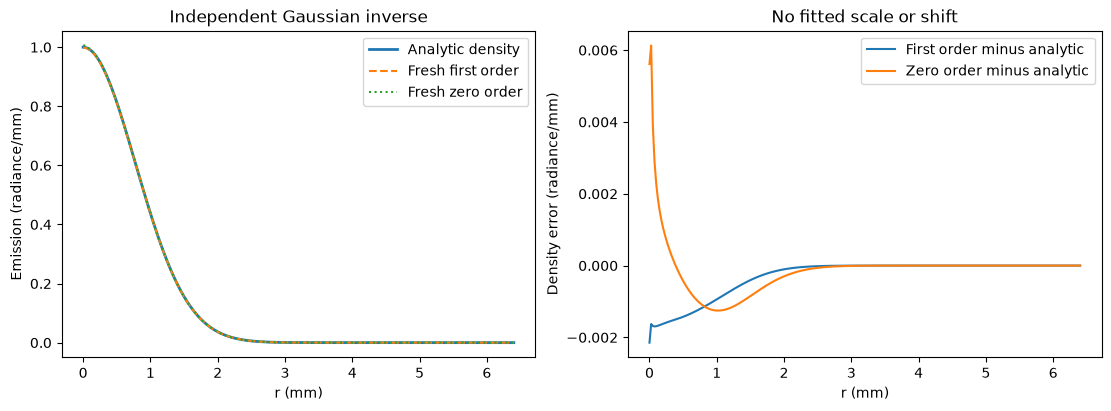

In [3]:
r = np.arange(257)*DR
gaussian = np.exp(-(r/1.1)**2)
gaussian_projection = np.sqrt(np.pi)*1.1*gaussian
g_first = inverse_transform(gaussian_projection, DR, 1)
g_zero = inverse_transform(gaussian_projection, DR, 0)
g_forward = forward_transform(gaussian, DR, 1)
forward_error = np.linalg.norm(g_forward-gaussian_projection)/np.linalg.norm(gaussian_projection)
inverse_error = np.linalg.norm(g_first-gaussian)/np.linalg.norm(gaussian)
assert forward_error < 0.015 and inverse_error < 0.015
print('Gaussian forward relative L2 error:', forward_error)
print('Gaussian inverse relative L2 error:', inverse_error)
_, _, clean_projection = synthetic_fields(seed=240)
noise_chi_square = float(np.mean(((projection-clean_projection)/NOISE_STD)**2))
model_error = float(np.linalg.norm(forward_transform(truth[0], DR, 1)-clean_projection[0])/np.linalg.norm(clean_projection))
assert 0.96 < noise_chi_square < 1.04
print('Bound acquisition noise chi-square/sample:', noise_chi_square)
print('Independent analytic vs numerical forward relative L2 error:', model_error)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].plot(r, gaussian, label='Analytic density', linewidth=2)
axes[0].plot(r, g_first, '--', label='Fresh first order')
axes[0].plot(r, g_zero, ':', label='Fresh zero order')
axes[0].set(xlabel='r (mm)', ylabel='Emission (radiance/mm)', title='Independent Gaussian inverse')
axes[0].legend()
axes[1].plot(r, g_first-gaussian, label='First order minus analytic')
axes[1].plot(r, g_zero-gaussian, label='Zero order minus analytic')
axes[1].set(xlabel='r (mm)', ylabel='Density error (radiance/mm)', title='No fitted scale or shift')
axes[1].legend()
plt.show()

### Results on the bound noisy acquisition

All numerical values in this section refer to these observations and the actual
synthetic emission truth. **Upstream** means the archived independent run;
**fresh** means the local calculations in this notebook. No paper-reported
number is mixed into this table. NCC is the flattened cosine without mean
subtraction. NRMSE is RMS density error divided by the truth's dynamic range.
The evaluator scores every sample without alignment or gain fitting.

The image panels show the radiance projection and density images with distinct
units. Density reconstructions share a physical color scale. Residuals have
their own explicit color scales. Radial profiles and paired metric panels
compare the two hold orders and their separately identified upstream results.

| Result | NCC | Dynamic-range NRMSE |
|---|---:|---:|
| Upstream first | 0.999826609 | 0.004119802 |
| Fresh first | 0.999826609 | 0.004119802 |
| Upstream zero | 0.999041353 | 0.009664078 |
| Fresh zero | 0.999041353 | 0.009664078 |

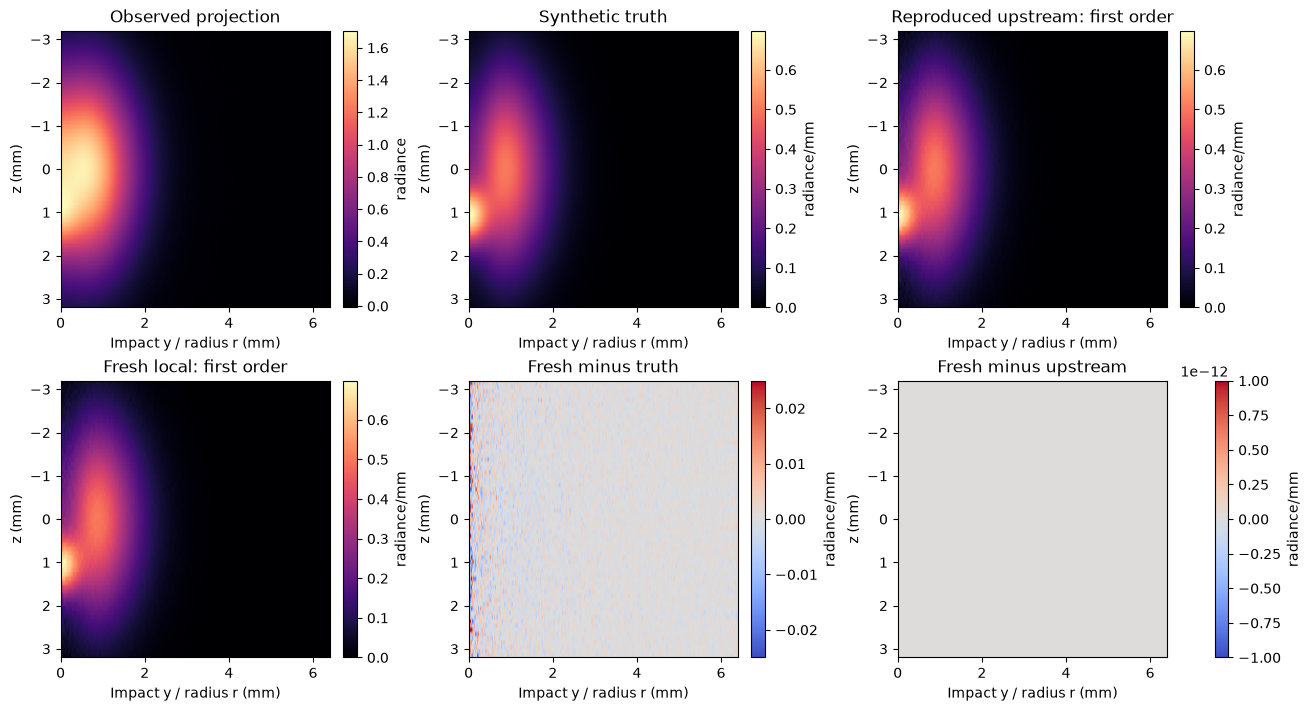

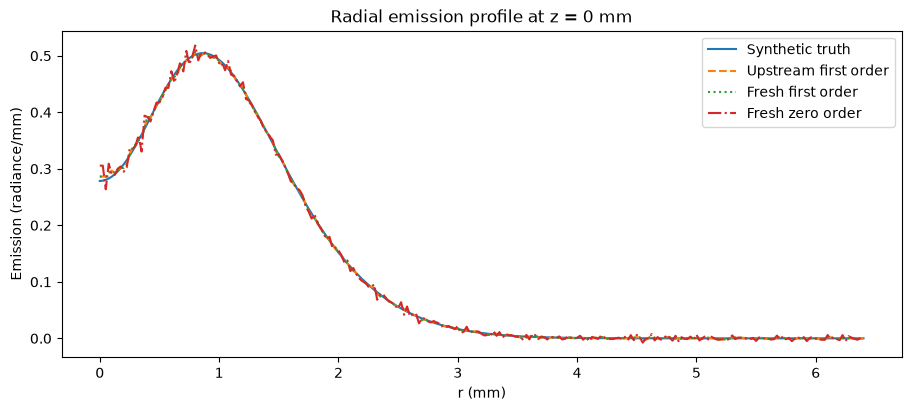

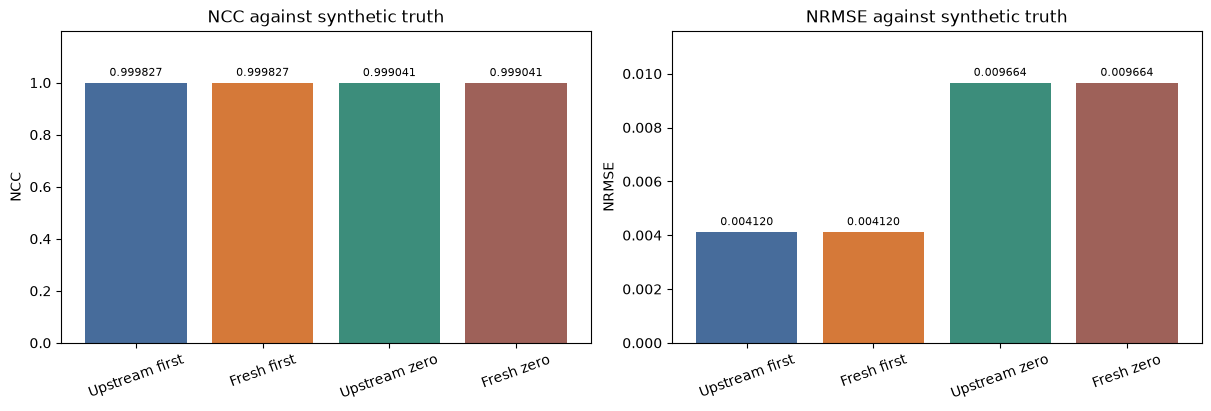

In [4]:
measurements = {
    'Upstream first': comparison_metrics(upstream, truth),
    'Fresh first': comparison_metrics(fresh, truth),
    'Upstream zero': comparison_metrics(upstream_zero, truth),
    'Fresh zero': comparison_metrics(fresh_zero, truth),
}
rows = ['| Result | NCC | Dynamic-range NRMSE |', '|---|---:|---:|']
for name, values in measurements.items():
    rows.append(f"| {name} | {values['ncc']:.9f} | {values['nrmse']:.9f} |")
display(Markdown('\n'.join(rows)))
plot_comparison(projection, truth, upstream, fresh)
plt.show()
plot_profiles(truth, upstream, fresh, fresh_zero)
plt.show()
plot_metric_bars(measurements)
plt.show()

### Standalone evaluation of the fresh submission

The following command scores the just-written submission in a separate process.
Thresholds were fixed from the upstream run before implementing the local
method: 0.9 times baseline NCC and 1.1 times baseline NRMSE. The Judge uses no
solver imports and the same independently checked metric conventions.

In [5]:
completed = subprocess.run([sys.executable, str(ROOT/'evaluation/judge.py'),
    '--prediction', str(ROOT/'output/reconstruction.npz'),
    '--report', str(ROOT/'output/judge_report.json')], capture_output=True, text=True)
assert completed.returncode == 0, completed.stderr
report = json.loads((ROOT/'output/judge_report.json').read_text())
assert report['passed']
for key in ['ncc', 'nrmse']:
    assert abs(report['metrics'][key]-measurements['Fresh first'][key]) < 1e-12
print(json.dumps(report, indent=2))
notebook_measurement = {'first_order_runtime_seconds': first_order_seconds,
    'zero_order_runtime_seconds': zero_order_seconds, 'measurements': measurements,
    'gaussian_forward_relative_l2': float(forward_error),
    'gaussian_inverse_relative_l2': float(inverse_error),
    'noise_chi_square_per_sample': noise_chi_square,
    'numerical_forward_relative_l2': model_error}
print(json.dumps(notebook_measurement, indent=2))

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9998266089834679,
    "nrmse": 0.004119801658595976
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.8998439480851215
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 0.004531781824455574
    }
  },
  "errors": []
}
{
  "first_order_runtime_seconds": 0.0020130000775679946,
  "zero_order_runtime_seconds": 0.0015851999633014202,
  "measurements": {
    "Upstream first": {
      "ncc": 0.9998266089834683,
      "nrmse": 0.004119801658595976
    },
    "Fresh first": {
      "ncc": 0.9998266089834683,
      "nrmse": 0.004119801658595976
    },
    "Upstream zero": {
      "ncc": 0.9990413531966799,
      "nrmse": 0.009664078390355772
    },
    "Fresh zero": {
      "ncc": 0.9990413531966799,
      "nrmse": 0.009664078390355772
    }
  },
  "gaussian_forward_relative_l2": 0.0014181075628600806,
  "gaussian_inverse_relative_l2": 0.0018207107299165032,
  "noise_chi_square_per

## 6. Conclusion

The fresh first-order transform agrees with the independent upstream run and
recovers the physical emission scale. The zero-order comparison has larger
errors for this smooth source, consistent with its different derivative/hold
approximation. Small negative values are retained as noise fluctuations, and
the center/edge copies remain a documented numerical approximation.

Upstream parity establishes reproduction of the selected release. Analytic
pairs, line-integral quadrature, conservation and spacing checks add independent
physical evidence; Judge success alone would not provide this evidence.
These synthetic results do not validate experimental plasma thermometry,
unknown-axis recovery, non-axisymmetric sources, radiative transfer or the
other algorithms in the comparison paper. Exact revisions, data hashes,
warnings, licenses, test commands and gate status are in `test/validation.md`.